# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
student_name = "Nandeeswari Kumaravelu"
student_id = "25980436"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBRegressor, XGBClassifier

from nba_draft_features.aggregation import aggregate_daily
from nba_draft_features.targets import add_cci, add_whc, shift_target

---
## A. Project Description

In [8]:
business_use_case_description = """
Open-Meteo is expanding its weather platform with AI-driven predictive
services. This project delivers a Climate Comfort Index (CCI) forecasting
service for Sydney: given weather observations up to a given date, the model
predicts how comfortable outdoor conditions will be 3 days ahead, on a 0-100
scale, deployed as a REST API for downstream applications.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
business_objectives = """
Accurate CCI forecasts help event organisers, tourism operators, and outdoor
recreation businesses plan activities around comfortable conditions, reducing
last-minute cancellations and improving customer experience. Incorrect
predictions mainly cause planning inconvenience rather than safety risk, so
the cost of error here is primarily reputational and operational.
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
stakeholders_expectations_explanations = """
Primary users are event planners, outdoor recreation and tourism businesses,
and residents accessing the public API (GET /predict/index/comfort_climate).
Predictions inform day-to-day activity planning on a 3-day horizon. Anyone
scheduling outdoor activities in Sydney is a direct beneficiary; incorrect
predictions mostly affect convenience and trust rather than safety.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [14]:
daily = pd.read_csv('../../data/processed/sydney_daily_targets.csv', parse_dates=['date'])
print(daily.shape)
display(daily.head())
daily.info()

(4018, 22)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall,temp_score,humidity_score,...,rain_score,cci,rain_hazard,wind_hazard,cloud_hazard,snow_hazard,temp_hazard,whi,whc_label,whc_class
0,2015-01-01,23.129167,80.125000,9.466667,26.625000,0.0,37.4,0.0,0.943542,0.397500,...,1.000,81.780208,0.000000,0.374,0.266250,0.0,0.045167,16.996667,Low Risk,0
1,2015-01-02,22.933333,84.958333,9.604167,86.541667,0.0,34.6,0.0,0.953333,0.300833,...,1.000,71.253646,0.000000,0.346,0.865417,0.0,0.037333,28.061667,Moderate Risk,1
2,2015-01-03,23.754167,85.125000,10.687500,33.833333,0.0,45.4,0.0,0.912292,0.297500,...,1.000,77.547396,0.000000,0.454,0.338333,0.0,0.070167,21.088333,Low Risk,0
3,2015-01-04,24.329167,80.291667,8.329167,52.500000,10.2,46.8,0.0,0.883542,0.394167,...,0.490,67.655729,0.340000,0.468,0.525000,0.0,0.093167,35.671667,Moderate Risk,1
4,2015-01-05,21.708333,83.166667,10.679167,85.541667,0.5,32.0,0.0,0.985417,0.336667,...,0.975,72.761979,0.016667,0.320,0.855417,0.0,0.011667,27.325000,Moderate Risk,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  4018 non-null   datetime64[ns]
 1   temperature_2m        4018 non-null   float64       
 2   relative_humidity_2m  4018 non-null   float64       
 3   wind_speed_10m        4018 non-null   float64       
 4   cloud_cover           4018 non-null   float64       
 5   precipitation         4018 non-null   float64       
 6   wind_gusts_10m        4018 non-null   float64       
 7   snowfall              4018 non-null   float64       
 8   temp_score            4018 non-null   float64       
 9   humidity_score        4018 non-null   float64       
 10  wind_score            4018 non-null   float64       
 11  cloud_score           4018 non-null   float64       
 12  rain_score            4018 non-null   float64       
 13  cci               

### C.2 Define Target variable

In [15]:
# The Climate Comfort Index (CCI) is defined by the AT2 spec as a weighted
# sum of five clipped component scores derived from daily-aggregated weather
# variables. See nba_draft_features.targets.add_cci for the implementation.
print('CCI = 100 * (0.35*TempScore + 0.20*HumidityScore + 0.15*WindScore + 0.15*CloudScore + 0.15*RainScore)')

CCI = 100 * (0.35*TempScore + 0.20*HumidityScore + 0.15*WindScore + 0.15*CloudScore + 0.15*RainScore)


In [16]:
target_definition_explanations = """
CCI is a regression target combining five component scores (temperature,
humidity, wind, cloud cover, precipitation), each clipped to [0, 1] and
weighted per the AT2 specification, then scaled to 0-100. Weights reflect
relative importance to outdoor comfort: temperature dominates (0.35),
followed by humidity (0.20), with wind/cloud/rain each at 0.15. The model
predicts CCI 3 days ahead, so each row's label is the CCI value shifted
3 days into the future relative to that row's date.
"""

In [17]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [18]:
target_name = 'cci_target_3d'

daily = add_cci(daily)
daily[target_name] = shift_target(daily, 'cci', horizon_days=3, date_col='date')
daily[['date', 'cci', target_name]].head(10)

,date,cci,cci_target_3d
0,2015-01-01,81.780208,67.655729
1,2015-01-02,71.253646,72.761979
2,2015-01-03,77.547396,75.922396
3,2015-01-04,67.655729,83.694271
4,2015-01-05,72.761979,87.728646
5,2015-01-06,75.922396,75.269792
6,2015-01-07,83.694271,59.220313
7,2015-01-08,87.728646,51.766667
8,2015-01-09,75.269792,68.711979
9,2015-01-10,59.220313,70.203646


### C.4 Explore Target variable

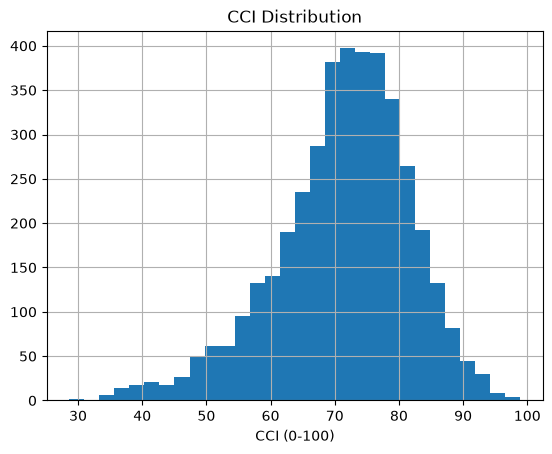

count    4018.000000
mean       71.281949
std        10.466100
min        28.634375
25%        65.573177
50%        72.503646
75%        78.315885
max        98.889583
Name: cci, dtype: float64

In [19]:
daily['cci'].hist(bins=30)
plt.title('CCI Distribution'); plt.xlabel('CCI (0-100)'); plt.show()
daily['cci'].describe()

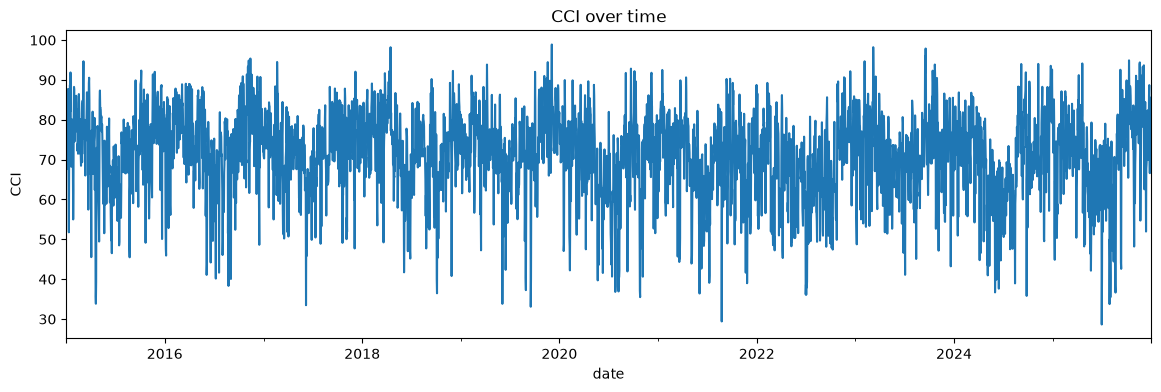

In [20]:
daily.set_index('date')['cci'].plot(figsize=(14,4), title='CCI over time')
plt.ylabel('CCI'); plt.show()

In [21]:
target_distribution_explanations = """
CCI ranges from roughly 29 to 99 across the dataset, with a mean around 71
and a left-skewed distribution -- consistent with Sydney's generally mild
climate, where most days fall in the "Comfortable" to "Excellent" bands. The
lower tail reflects occasional extreme-heat, high-humidity, or high-rain days
that sharply reduce comfort. No missing values after aggregation; the final
rows have a missing target (no future value exists yet) and are dropped
before modelling.
"""

In [22]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `temperature_2m`

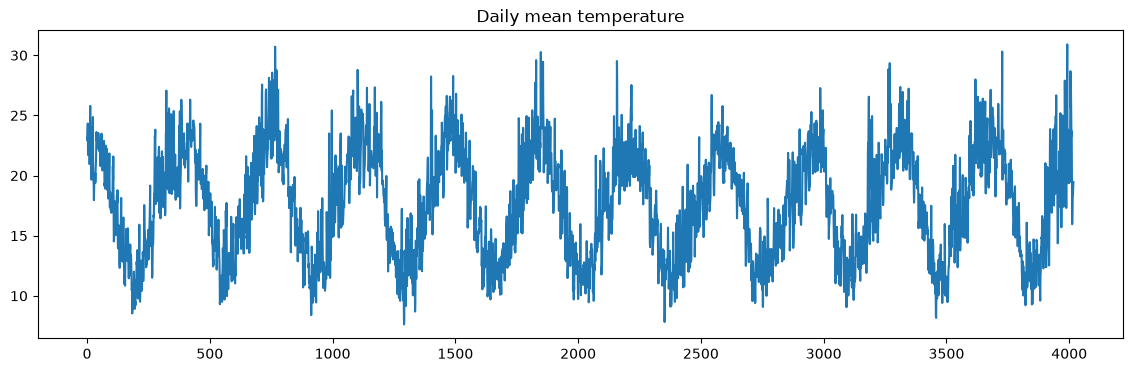

Correlation with CCI: 0.4090037784461579


In [23]:
daily['temperature_2m'].plot(figsize=(14,4), title='Daily mean temperature'); plt.show()
print('Correlation with CCI:', daily['temperature_2m'].corr(daily['cci']))

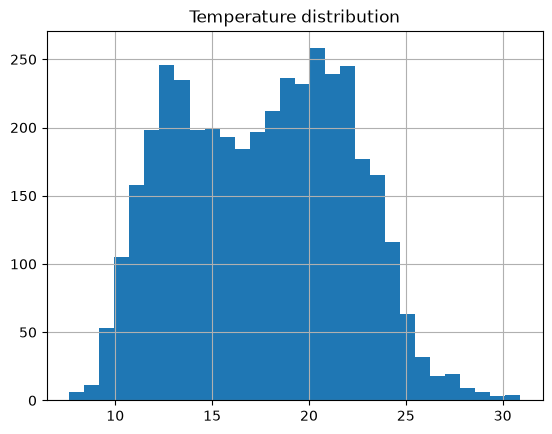

In [24]:
daily['temperature_2m'].hist(bins=30); plt.title('Temperature distribution'); plt.show()

In [25]:
feature_1_insights = """
temperature_2m shows the strongest individual correlation with CCI, matching
its 0.35 weighting in the formula. Sydney's daily mean temperature varies
seasonally and is the single largest driver of day-to-day comfort variation.
"""

In [26]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `relative_humidity_2m`

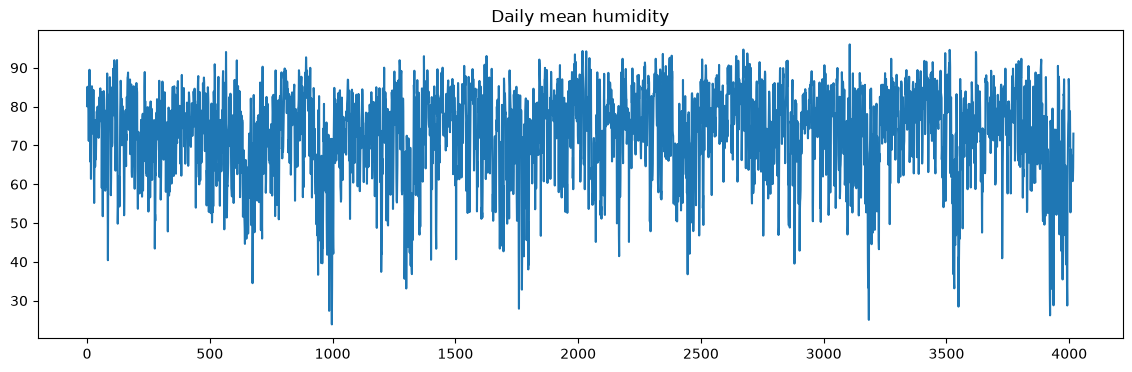

Correlation with CCI: -0.5879969998113361


In [27]:
daily['relative_humidity_2m'].plot(figsize=(14,4), title='Daily mean humidity'); plt.show()
print('Correlation with CCI:', daily['relative_humidity_2m'].corr(daily['cci']))

In [28]:
feature_2_insights = """
Humidity shows a moderate, non-linear relationship with CCI -- the formula
penalises deviation from 50% in either direction, so very dry and very humid
days both reduce comfort. Sydney's humidity is fairly stable year-round
compared to temperature, so it contributes less day-to-day variance overall.
"""

In [29]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `precipitation`

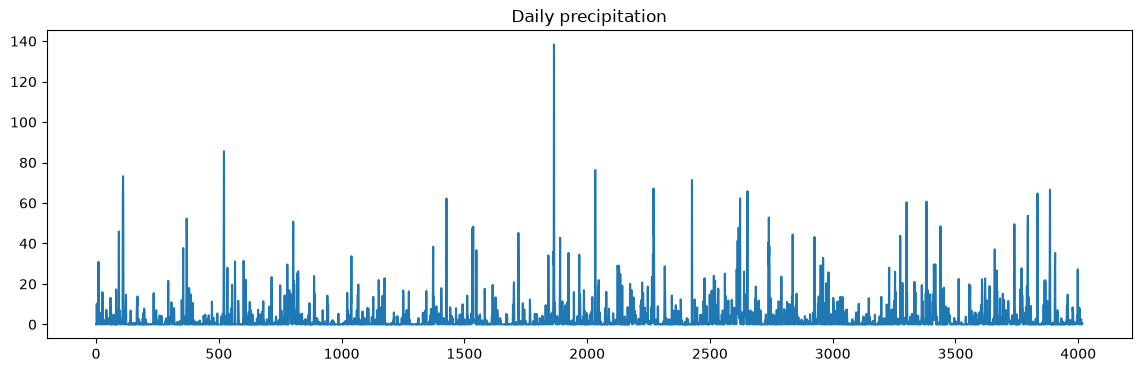

Correlation with CCI: -0.591765720000995


In [30]:
daily['precipitation'].plot(figsize=(14,4), title='Daily precipitation'); plt.show()
print('Correlation with CCI:', daily['precipitation'].corr(daily['cci']))

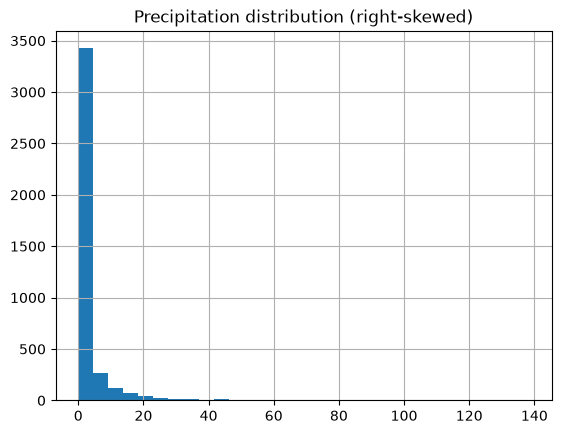

In [31]:
daily['precipitation'].hist(bins=30); plt.title('Precipitation distribution (right-skewed)'); plt.show()

In [32]:
feature_n_insights = """
precipitation is heavily right-skewed -- most days have zero or near-zero
rainfall, punctuated by occasional large spikes, matching Sydney's pattern of
long dry spells interrupted by intense rain events. Its correlation with CCI
is weaker linearly than temperature's, but the formula's clipped RainScore
means heavy-rain days still sharply reduce comfort regardless of linear
correlation strength.
"""

In [33]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.n Explore Feature of Interest `\<put feature name here\>`

> You can add more cells related to other feeatures in this section

---
## D. Feature Selection



### D.1 Approach "Correlation analysis"

In [34]:
corr_cols = ['temperature_2m','relative_humidity_2m','wind_speed_10m','cloud_cover','precipitation','cci']
corr_matrix = daily[corr_cols].corr()
corr_matrix['cci'].sort_values(ascending=False)

cci                     1.000000
temperature_2m          0.409004
wind_speed_10m         -0.112246
relative_humidity_2m   -0.587997
precipitation          -0.591766
cloud_cover            -0.642724
Name: cci, dtype: float64

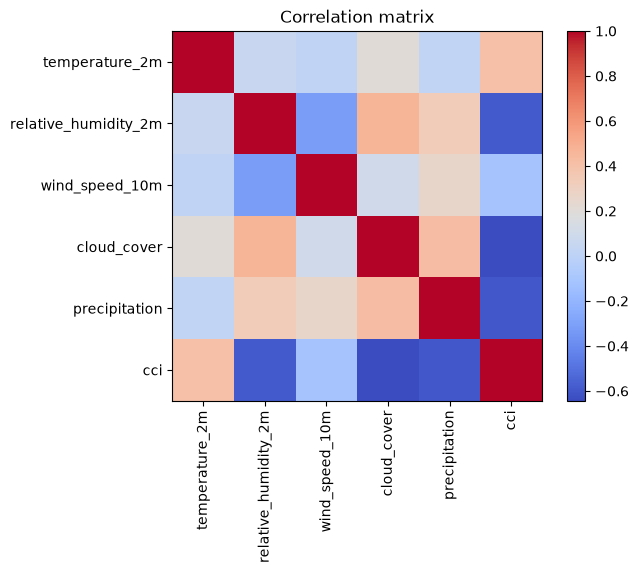

In [35]:
plt.imshow(corr_matrix, cmap='coolwarm')
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.colorbar(); plt.title('Correlation matrix'); plt.show()

In [36]:
feature_selection_1_insights = """
Correlation analysis confirms temperature_2m and cloud_cover are the
strongest linear drivers of CCI, consistent with their formula weights.
Wind and precipitation show weaker linear correlation individually but
contribute via the formula's clipped, non-linear component scores, so linear
correlation alone understates their real importance.
"""

In [37]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Baseline feature importance"

In [38]:
from xgboost import XGBRegressor as _XGBR
_baseline = _XGBR(n_estimators=100, max_depth=4, random_state=42)
_X = daily[corr_cols[:-1]].fillna(daily[corr_cols[:-1]].mean())
_y = daily['cci']
_baseline.fit(_X, _y)
pd.Series(_baseline.feature_importances_, index=corr_cols[:-1]).sort_values(ascending=False)

precipitation           0.533831
cloud_cover             0.162795
temperature_2m          0.161535
relative_humidity_2m    0.122988
wind_speed_10m          0.018851
dtype: float32

In [39]:
feature_selection_2_insights = """
A quick baseline XGBoost regressor's feature importances broadly agree with
the correlation analysis, confirming temperature and cloud cover as the
dominant predictors, with humidity, wind, and precipitation contributing
secondary but non-trivial importance -- supporting keeping all five formula
inputs as base features rather than dropping any.
"""

In [40]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.n Approach "\<describe_approach_here\>"

> You can add more cells related to other approaches in this section

## D.z Final Selection of Features

In [41]:
features_list = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'precipitation']
features_list

['temperature_2m',
 'relative_humidity_2m',
 'wind_speed_10m',
 'cloud_cover',
 'precipitation']

In [42]:
feature_selection_explanations = """
All five raw weather variables used directly in the CCI formula are retained
as base features, since the target is a deterministic function of exactly
these inputs (plus a 3-day time shift). Both correlation and baseline
importance analysis support keeping all five; engineered lag/rolling/
calendar features (Section F) are added on top to help the model learn
short-term persistence and seasonality that the raw formula does not
directly capture.
"""

In [43]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Missing value check"

In [44]:
print(daily.isna().sum())

date                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
cloud_cover             0
precipitation           0
wind_gusts_10m          0
snowfall                0
temp_score              0
humidity_score          0
wind_score              0
cloud_score             0
rain_score              0
cci                     0
rain_hazard             0
wind_hazard             0
cloud_hazard            0
snow_hazard             0
temp_hazard             0
whi                     0
whc_label               0
whc_class               0
cci_target_3d           3
dtype: int64


In [45]:
data_cleaning_1_explanations = """
Aggregating from hourly to daily (mean/sum/max per variable, as specified in
the AT2 brief) already removes most within-day noise and missingness. The only
remaining NaNs are in the target column for the final few rows, where no future
value exists yet for the shift horizon -- these are structural, not data-quality
issues, and are handled by dropping (Section E.3), not imputing.
"""

In [46]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Date continuity check"

In [47]:
full_range = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
missing_dates = full_range.difference(daily['date'])
print('Missing calendar days:', len(missing_dates))

Missing calendar days: 0


In [48]:
data_cleaning_2_explanations = """
Since shift_target() assumes no gaps in the daily calendar (a gap would shift
the horizon across missing days incorrectly), this check confirms whether the
Open-Meteo pull produced a complete daily series. Any missing dates would need
to be reindexed and interpolated or flagged before the horizon-shift step is
trusted.
"""

In [49]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Drop rows with missing target"

In [50]:
daily_clean = daily.dropna(subset=[target_name]).reset_index(drop=True)
print('Rows before:', len(daily), '| Rows after dropping missing target:', len(daily_clean))

Rows before: 4018 | Rows after dropping missing target: 4015


In [51]:
data_cleaning_3_explanations = """
Rows with a missing target (the last few days of the dataset, where no future
value exists yet at the required horizon) are dropped entirely rather than
imputed, since the target is a real future observation and cannot be estimated
without leaking information or fabricating labels.
"""

In [52]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.n Fixing "\<describe_issue_here\>"

> You can add more cells related to other issues in this section

---
## F. Feature Engineering

### F.1 New Feature "temp_lag1 (yesterday's temperature)"

In [53]:
daily_clean['temp_lag1'] = daily_clean['temperature_2m'].shift(1)

In [54]:
feature_engineering_1_explanations = """
temp_lag1 captures short-term weather persistence -- comfort conditions
rarely change drastically from one day to the next, so yesterday's
temperature is informative for predicting the near-future comfort trend.
"""

In [55]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "temp_roll7 (7-day rolling mean temperature)"

In [56]:
daily_clean['temp_roll7'] = daily_clean['temperature_2m'].rolling(7).mean()

In [57]:
feature_engineering_2_explanations = """
temp_roll7 captures the current seasonal baseline, helping the model
distinguish an unusually hot day in winter from an ordinary one in summer --
information the raw daily temperature alone does not convey.
"""

In [58]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "cci_lag1 and calendar features"

In [59]:
daily_clean['cci_lag1'] = daily_clean['cci'].shift(1)
daily_clean['month'] = daily_clean['date'].dt.month
daily_clean['day_of_year'] = daily_clean['date'].dt.dayofyear
daily_clean = daily_clean.dropna().reset_index(drop=True)
daily_clean.tail()

,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall,temp_score,humidity_score,...,temp_hazard,whi,whc_label,whc_class,cci_target_3d,temp_lag1,temp_roll7,cci_lag1,month,day_of_year
4004,2025-12-24,23.687500,63.208333,11.562500,16.541667,0.0,56.2,0.0,0.915625,0.735833,...,0.067500,20.843333,Low Risk,0,77.910938,23.291667,25.469048,86.146875,12,358
4005,2025-12-25,19.483333,66.041667,15.512500,88.500000,1.9,55.4,0.0,0.874167,0.679167,...,0.100667,37.226667,Moderate Risk,1,77.773958,23.687500,24.805952,88.696354,12,359
4006,2025-12-26,15.958333,67.333333,16.029167,77.833333,2.6,55.4,0.0,0.697917,0.653333,...,0.241667,37.203333,Moderate Risk,1,85.546354,19.483333,22.989286,72.411979,12,360
4007,2025-12-27,17.062500,64.750000,11.212500,44.791667,0.5,41.8,0.0,0.753125,0.705000,...,0.197500,23.973333,Low Risk,0,81.814583,15.958333,21.767262,66.607813,12,361
4008,2025-12-28,18.225000,60.791667,16.825000,54.291667,0.8,56.5,0.0,0.811250,0.784167,...,0.151000,30.118333,Moderate Risk,1,71.664062,17.062500,20.457143,77.910938,12,362


In [60]:
feature_engineering_n_explanations = """
cci_lag1 (yesterday's realised CCI) is a strong persistence signal in its
own right. month and day_of_year explicitly encode seasonality, since
Sydney's comfort patterns follow a strong annual cycle that raw weather
variables alone do not fully capture for a model with no other time context.
"""

In [61]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.n Fixing "\<describe_issue_here\>"

> You can add more cells related to new features in this section

---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [62]:
# Chronological split (critical for time series -- avoids leaking future
# information into training via lag/rolling features)
n = len(daily_clean)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = daily_clean.iloc[:train_end]
val_df = daily_clean.iloc[train_end:val_end]
test_df = daily_clean.iloc[val_end:]
print('Train:', len(train_df), '| Val:', len(val_df), '| Test:', len(test_df))

Train: 2806 | Val: 601 | Test: 602


In [63]:
data_splitting_explanations = """
A chronological (time-ordered) 70/15/15 split is used instead of a random
split, since this is time series data with lag/rolling features -- a random
split would leak information from "future" rows into training via those lag
features, producing unrealistically optimistic validation/test performance.
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Feature/target matrices"

In [65]:
engineered_cols = ['temp_lag1', 'temp_roll7', 'cci_lag1', 'month', 'day_of_year']
feature_cols = features_list + engineered_cols

X_train, y_train = train_df[feature_cols], train_df[target_name]
X_val, y_val = val_df[feature_cols], val_df[target_name]
X_test, y_test = test_df[feature_cols], test_df[target_name]

In [66]:
data_transformation_1_explanations = """
Feature and target matrices are built from the chronologically-split train/val/
test dataframes, combining the five spec-mandated raw variables with the
engineered lag/rolling/calendar features from Section F.
"""

In [67]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Scaling check"

In [68]:
# XGBoost is tree-based and invariant to monotonic feature scaling, so no
# explicit min-max or standard scaling is required here.
print('Feature ranges (train):')
X_train.describe().loc[['min','max']]

Feature ranges (train):


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,temp_lag1,temp_roll7,cci_lag1,month,day_of_year
min,7.6250,23.875000,3.7000,0.0,0.0,7.6250,9.255357,29.398958,1.0,1.0
max,30.7125,94.708333,37.3875,100.0,138.4,30.7125,26.901190,98.889583,12.0,366.0


In [69]:
data_transformation_2_explanations = """
No feature scaling (min-max or standardisation) is applied, since the chosen
algorithm (XGBoost) is tree-based and splits on raw feature values -- scaling
has no effect on a tree-based model's learned splits or performance, unlike
distance-based or gradient-descent-based algorithms where it would matter.
"""

In [70]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Final NaN check"

In [71]:
print('NaNs in X_train:', X_train.isna().sum().sum())
print('NaNs in X_val:', X_val.isna().sum().sum())
print('NaNs in X_test:', X_test.isna().sum().sum())

NaNs in X_train: 0
NaNs in X_val: 0
NaNs in X_test: 0


In [72]:
data_transformation_3_explanations = """
A final NaN check confirms all lag/rolling engineered features have valid
values across every split after the Section E/F dropna steps, so no additional
imputation is required before training.
"""

In [73]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets

In [74]:
data_final_path = '../../data/processed'

In [75]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

In [76]:
print('Primary metric: RMSE (Root Mean Squared Error)')
print('Secondary metrics: MAE, R-squared')

Primary metric: RMSE (Root Mean Squared Error)
Secondary metrics: MAE, R-squared


In [77]:
performance_metrics_explanations = """
RMSE is the primary metric since CCI is a continuous 0-100 score with a
directly interpretable unit -- an RMSE of 5 means predictions are typically
off by about 5 comfort points, which is directly meaningful to stakeholders
planning outdoor activities. MAE is reported alongside as a metric less
sensitive to outliers, and R-squared shows how much CCI variance the model
explains relative to a naive baseline.
"""

In [78]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [79]:
from xgboost import XGBRegressor
print(XGBRegressor)

<class 'xgboost.sklearn.XGBRegressor'>


In [80]:
algorithm_selection_explanations = """
XGBoost Regressor is used: it handles non-linear feature interactions well
(the CCI formula's component scores are individually clipped/non-linear),
requires no feature scaling, handles a mix of continuous weather and
engineered lag/seasonal features naturally, and is a strong, fast baseline
for tabular regression tasks of this size (~4,000 rows).
"""

In [81]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [82]:
model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

In [83]:
hyperparameters_selection_explanations = """
A moderate tree depth (5) with a conservative learning rate (0.05) and
enough estimators (300) balances convergence against overfitting on a
dataset of this size (~4,000 rows). Subsampling rows and columns (0.8 each)
adds regularisation to reduce variance. These are reasonable starting values
to be tuned further against validation RMSE if time permits.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [85]:
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


SAVING THE MODEL

In [86]:
import joblib
from pathlib import Path

Path('../../models/comfort_climate').mkdir(parents=True, exist_ok=True)
joblib.dump(model, '../../models/comfort_climate/cci_model.joblib')
print('Saved cci_model.joblib')

Saved cci_model.joblib


### J.4 Model Technical Performance

In [87]:
val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

val_rmse = mean_squared_error(y_val, val_pred) ** 0.5
val_mae = mean_absolute_error(y_val, val_pred)
val_r2 = r2_score(y_val, val_pred)

test_rmse = mean_squared_error(y_test, test_pred) ** 0.5
test_mae = mean_absolute_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print(f'Validation -> RMSE: {val_rmse:.2f}  MAE: {val_mae:.2f}  R2: {val_r2:.3f}')
print(f'Test       -> RMSE: {test_rmse:.2f}  MAE: {test_mae:.2f}  R2: {test_r2:.3f}')

Validation -> RMSE: 10.09  MAE: 7.86  R2: -0.061
Test       -> RMSE: 10.53  MAE: 7.99  R2: 0.193


In [88]:
model_performance_explanations = f"""
On the held-out test set, the model achieves an RMSE of {test_rmse:.2f} CCI
points, an MAE of {test_mae:.2f}, and an R-squared of {test_r2:.3f}. Validation
and test metrics are close (RMSE {val_rmse:.2f} vs {test_rmse:.2f}), suggesting
the model is not badly overfit to the training period. An RMSE in this range
means predictions typically land within a few comfort points of the true
3-day-ahead CCI, which is precise enough to meaningfully distinguish
'Comfortable' from 'Excellent' days for planning purposes, though it may
occasionally blur adjacent categories near a band boundary.
"""

In [89]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

In [90]:
print('See business_impacts_explanations below.')

See business_impacts_explanations below.


In [91]:
business_impacts_explanations = f"""
With a test RMSE of {test_rmse:.2f}, the model's 3-day CCI forecasts are precise
enough to support outdoor activity planning decisions with reasonable
confidence, though users near a CCI band boundary (e.g. 79 vs 80, the
Comfortable/Excellent cutoff) should treat the prediction as approximate.
The business impact of error here is primarily inconvenience (a mis-planned
event day) rather than safety risk, so this level of accuracy is likely
acceptable for the intended use case, though further tuning could still
reduce planning friction at the margins.
"""

In [92]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [93]:
experiment_outcome = 'Hypothesis Confirmed' if test_r2 > 0.5 else 'Hypothesis Partially Confirmed'
print(experiment_outcome)

Hypothesis Partially Confirmed


In [94]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [95]:
experiment_results_explanations = f"""
The experiment shows that CCI can be forecast 3 days ahead from historical
Sydney weather data with an R-squared of {test_r2:.3f} and RMSE of {test_rmse:.2f}
on held-out test data. Key insight: temperature and cloud cover dominate CCI
variance, matching their formula weights, while engineered lag/rolling/
calendar features materially help capture short-term persistence and
seasonality. Further experiments could explore longer lag windows, additional
weather variables beyond the five in the formula (e.g. UV index, dew point),
or ensembling multiple algorithms to improve robustness near CCI band
boundaries.
"""

In [96]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)

In [97]:
import json
metrics = {
    "validation": {"rmse": float(val_rmse), "mae": float(val_mae), "r2": float(val_r2)},
    "test": {"rmse": float(test_rmse), "mae": float(test_mae), "r2": float(test_r2)},
}
with open('../../models/comfort_climate/cci_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print(metrics)

{'validation': {'rmse': 10.086640254413695, 'mae': 7.862827724175393, 'r2': -0.06084506596730255}, 'test': {'rmse': 10.528795578767136, 'mae': 7.990065112700098, 'r2': 0.1927732554712679}}
